# 02 · Build the flood labels

**Goal.** Turn the 236 satellite flood maps inside the window into one number per 5 km square per season: the **flooded fraction**, the share of the square that was underwater (0 to 1).

**Inputs.** The frozen GISTDA list (`data_small/gistda_filelist_2026-11-14.json`), the flood-map shapefiles, one CHIRPS file (for the grid), and the JRC permanent-water map from Planetary Computer.
**Outputs.**
- `flood_data/interim/label_*.npy`: full-grid counts and fractions (large, not in git)
- `data_small/labels.parquet`: **the label table**, one row per study square and season (small, in git)
- `data_small/label_passes.csv`: which passes were used, and how much water each saw
- `figures/fig_labels_maps.png`

**The rules, in plain words** (the same ones tested in October):
1. Split every 5 km square into 10 × 10 fine cells (about 550 m each).
2. A fine cell counts as **flooded** in a season if **at least 2 passes** saw water there. One pass alone could be a radar artefact.
3. The flooded fraction of a square is the share of its 100 fine cells that are flooded.
4. Rivers and lakes are not floods, so we **subtract the permanent-water fraction** (JRC) and stop at zero.
5. Each pass only photographs a strip of the country, so we keep only squares **photographed at least 5 times in every season**: the study area.

**Steps**
1. List the passes inside the window
2. Set up the fine grid
3. Draw every pass onto the grid (the slow step, about 10 minutes, saved for reuse)
4. Check against the October run
5. From fine cells to 5 km fractions, and the study area
6. Permanent water from JRC
7. The final label, and a check against the proposal numbers
8. Save the label table and maps

## Setup

In [1]:
import sys, json, warnings
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from config import *

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray as rxr
import geopandas as gpd
import shapely
import rasterio.features
from affine import Affine
import matplotlib.pyplot as plt
from src.flood_utils import savefig

warnings.filterwarnings("ignore")      # GISTDA files trigger harmless Thai-encoding warnings
F = FINE_FACTOR
print("snapshot:", GISTDA_SNAPSHOT, "| window:", FLOOD_WINDOW, "| fine factor:", F)

snapshot: 2026-11-14 | window: ('08-04', '10-21') | fine factor: 10


## Step 1 · List the passes inside the window

We read the frozen GISTDA list, not the live website, so the labels can't change under us. An entry counts as a satellite **pass** unless it is one of GISTDA's `floodtoday` index entries (no flood data) or an `oth_` entry (no download). The date comes from each entry's `datetime` field.

In [2]:
data = json.loads((SMALL_DIR / f"gistda_filelist_{GISTDA_SNAPSHOT}.json").read_text())

def category(scene):
    if scene.startswith("floodtoday"): return "floodtoday"
    if scene.startswith("oth_"):       return "other"
    return "pass"

rows = []
for e in data["files"]:
    scene = e.get("scene_name") or ""
    p = e.get("properties") or {}
    rows.append(dict(scene=scene, category=category(scene), sat=scene.split("_")[0],
                     datetime=p.get("datetime"), satellite=p.get("satellite"),
                     has_zip=any(f.get("type") == ".zip" for f in e.get("files", []))))
scenes = pd.DataFrame(rows)
scenes["date"] = pd.to_datetime(scenes["datetime"], errors="coerce", utc=True).dt.tz_localize(None)
scenes["year"] = scenes["date"].dt.year

md_ = scenes["date"].dt.strftime("%m-%d")
passes = scenes[(scenes.category == "pass") & scenes.has_zip &
                (md_ >= FLOOD_WINDOW[0]) & (md_ <= FLOOD_WINDOW[1])].copy()
passes["folder_ok"] = passes["scene"].map(lambda s: (RAW_GISTDA / s).is_dir())

print("passes inside the window, per year:")
print(passes.groupby("year").size().to_string())
print("missing on disk:", int((~passes.folder_ok).sum()))

passes inside the window, per year:
year
2024    57
2025    97
2026    82
missing on disk: 0


**What to check:** 57 / 97 / 82 passes (2026 has one more than in October, the 21 Oct S1D pass) and 0 missing.

In [3]:
# Which satellites? Mostly Sentinel-1 radar, plus Radarsat-2 and a few others.
pd.crosstab(passes["satellite"], passes["year"])

year,2024,2025,2026
satellite,,,
ALOS-2,1,0,0
COSMO-SkyMed 2,1,0,3
COSMO-SkyMed 4,1,0,4
COSMO-SkyMed-2 2nd Gen,0,0,1
PAZ,0,0,1
Radarsat-2,13,24,9
Sentinel-1A,39,44,0
Sentinel-1C,0,29,22
Sentinel-1D,0,0,37


## Step 2 · Set up the fine grid

The 5 km grid is the CHIRPS rainfall grid, so rain and floods line up square for square. Each square is split into 10 × 10 fine cells. A square is **land** if CHIRPS has a value there (CHIRPS is blank over the sea).

In [4]:
ref = rxr.open_rasterio(sorted(RAW_CHIRPS.glob("*.tif"))[0], masked=True).squeeze(drop=True)
H, W = ref.shape
land = ref.notnull().values
fine_transform = ref.rio.transform() * Affine.scale(1.0 / F, 1.0 / F)
fine_shape = (H * F, W * F)

print(f"5 km grid: {H} x {W} squares, {int(land.sum())} on land")
print(f"fine grid: {fine_shape[0]} x {fine_shape[1]} cells (~550 m)")

5 km grid: 299 x 169 squares, 35150 on land
fine grid: 2990 x 1690 cells (~550 m)


**What to check:** 299 × 169 squares and 35,150 on land, as in October.

## Step 3 · Draw every pass onto the fine grid

For each pass we draw two things on the fine grid:
- **flood**: the cells inside its flood polygons (1 = water seen)
- **hull**: the cells inside the convex hull around all its polygons, a rough outline of the area the satellite photographed

Adding them up over a season gives, for every fine cell, *how many passes saw water* and *roughly how many passes photographed it*.

A caveat for the paper: GISTDA shares the flood polygons but not the satellite footprint, so the hull is only a proxy for coverage. Inside a hull, a blank area can mean "dry" or "not really photographed".

This takes several minutes, so the results are saved, and the cell reloads them next time unless `REBUILD = True`.

In [5]:
def read_pass(scene):
    """Flood polygons of one pass, in lat/lon, ignoring Mac junk files."""
    shp = [p for p in (RAW_GISTDA / scene).glob("*.shp") if not p.name.startswith("._")]
    g = gpd.read_file(shp[0], columns=[], encoding="cp874")
    if g.crs is not None and g.crs.to_epsg() != 4326:
        g = g.to_crs(4326)
    return [shapely.make_valid(x) for x in g.geometry if x is not None and not x.is_empty]

def burn(geoms):
    return rasterio.features.rasterize([(x, 1) for x in geoms], out_shape=fine_shape,
                                       transform=fine_transform, fill=0, dtype="uint8")

In [6]:
REBUILD = False
paths = {y: (INTERIM / f"label_flood_count_{y}.npy", INTERIM / f"label_hull_count_{y}.npy") for y in YEARS}

if REBUILD or not all(a.exists() and b.exists() for a, b in paths.values()):
    log = []
    for year, grp in passes.groupby("year"):
        flood = np.zeros(fine_shape, dtype=np.uint8)
        hull = np.zeros(fine_shape, dtype=np.uint8)
        for row in grp.itertuples():
            geoms = read_pass(row.scene)
            if not geoms:
                continue
            m = burn(geoms)
            h = burn([shapely.GeometryCollection(geoms).convex_hull])
            flood += m
            hull += h
            log.append(dict(year=int(year), scene=row.scene, date=row.date.date(), satellite=row.satellite,
                            flood_cells=int(m.sum()), hull_cells=int(h.sum())))
        np.save(paths[year][0], flood)
        np.save(paths[year][1], hull)
        print(int(year), "done:", len(grp), "passes")
    pd.DataFrame(log).to_csv(SMALL_DIR / "label_passes.csv", index=False)
else:
    print("loading saved counts (set REBUILD = True to redo)")

flood_count = {y: np.load(paths[y][0]) for y in YEARS}
hull_count = {y: np.load(paths[y][1]) for y in YEARS}
plog = pd.read_csv(SMALL_DIR / "label_passes.csv")
plog.groupby("year").agg(passes=("scene", "count"), median_flood_cells=("flood_cells", "median"))

loading saved counts (set REBUILD = True to redo)


,passes,median_flood_cells
year,,
2024,57,1535.0
2025,97,1683.0
2026,82,324.5


**What to check:** three "done" lines (or "loading saved counts"), and the same pass counts as step 1. A pass with zero polygons is skipped, which would show up as a smaller number here.

## Step 4 · Check against the October run

The October script produced the same kind of counts (`win_flood_count_*.npy`). With the same rules and the same passes, **2024 and 2025 must match exactly**. 2026 should differ only where the extra 21 October pass saw water. This shows the rebuild reproduces the tested work.

In [7]:
for y in YEARS:
    old_f = np.load(INTERIM / f"win_flood_count_{y}.npy")
    old_h = np.load(INTERIM / f"win_hull_count_{y}.npy")
    df_ = int((old_f != flood_count[y]).sum())
    dh_ = int((old_h != hull_count[y]).sum())
    print(f"{y}: fine cells that differ from October: flood {df_:,}  hull {dh_:,}")

2024: fine cells that differ from October: flood 0  hull 0
2025: fine cells that differ from October: flood 0  hull 0
2026: fine cells that differ from October: flood 14,277  hull 275,145


**What to check:** 0 and 0 for 2024 and 2025. Some differences for 2026, all inside the new pass's strip.

## Step 5 · From fine cells to 5 km fractions, and the study area

Three numbers per square and season:
- `frac2`: share of the 100 fine cells seen flooded by **2 or more** passes (the main label, before removing permanent water)
- `frac1`: the same with **1 or more** passes (only for the sensitivity test)
- `cover`: the **average** hull count of the 100 fine cells, a rough "times photographed"

The study area is every land square with `cover ≥ 5` in all three seasons.

In [8]:
def coarse_share(a, k):
    """Share of the F x F fine cells in each square where the count is at least k."""
    return (a >= k).reshape(H, F, W, F).mean(axis=(1, 3))

def coarse_mean(a):
    return a.reshape(H, F, W, F).mean(axis=(1, 3))

frac2 = {y: coarse_share(flood_count[y], MIN_PASSES_FLOODED) for y in YEARS}
frac1 = {y: coarse_share(flood_count[y], 1) for y in YEARS}
cover = {y: coarse_mean(hull_count[y]) for y in YEARS}

study = land.copy()
for y in YEARS:
    study &= cover[y] >= MIN_COVER_PASSES
ever = study & np.any([frac2[y] > 0 for y in YEARS], axis=0)
print(f"study area: {int(study.sum())} squares ({study.sum() / land.sum():.0%} of land), "
      f"{int(ever.sum())} flooded in some season")

study area: 3974 squares (11% of land), 1391 flooded in some season


**What to check:** close to **3,974** squares and 1,391 ever flooded. The new pass can add a handful of squares, since it raises the 2026 photographed count in its strip.

## Step 6 · Permanent water from JRC

The radar flood maps include some permanent water (rivers, reservoirs, fish ponds). The **JRC Global Surface Water** map gives, for every 30 m pixel, the percentage of time water was seen there over 1984–2021. Averaged over a 5 km square and divided by 100, that is roughly the share of the square that is normally water. We load it at exactly the CHIRPS resolution (0.05°), so the squares line up, and save it so the download happens only once.

In [9]:
water_file = INTERIM / "jrc_water_frac_5km.npy"

if water_file.exists():
    water = np.load(water_file)
    print("loaded saved permanent-water map")
else:
    import pystac_client, planetary_computer, odc.stac
    catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                        modifier=planetary_computer.sign_inplace)
    bbox = [float(ref.x.min()) - 0.1, float(ref.y.min()) - 0.1, float(ref.x.max()) + 0.1, float(ref.y.max()) + 0.1]
    items = catalog.search(collections=["jrc-gsw"], bbox=bbox).item_collection()
    occ = odc.stac.load(items, bands=["occurrence"], bbox=bbox, crs="EPSG:4326",
                        resolution=GRID_RES_DEG, resampling="average", chunks={}).compute()
    occ = occ["occurrence"].squeeze()
    occ = occ.where(occ <= 100)                       # values above 100 are 'no data'
    if "latitude" in occ.dims:
        occ = occ.rename({"latitude": "y", "longitude": "x"})
    occ5 = occ.reindex(x=ref.x.values, y=ref.y.values, method="nearest", tolerance=0.06).values
    water = np.nan_to_num(occ5, nan=0.0) / 100.0
    np.save(water_file, water)
    print("downloaded from", len(items), "JRC tiles and saved")

print(f"permanent water in the study area: median {np.median(water[study]):.3f}, "
      f"squares with > 5% water: {int((water[study] > 0.05).sum())}")

loaded saved permanent-water map
permanent water in the study area: median 0.000, squares with > 5% water: 321


**What to check:** the median is close to 0 (most squares are dry land), with a few hundred squares above 5% (rivers, reservoirs).

## Step 7 · The final label, and a check against the proposal

**Label = flooded fraction − permanent-water fraction, never below 0.**

Then we rerun the baseline check from the proposal: predict each season from the average of the other two, and compare with predicting zero everywhere or one constant. Run on the **October counts** it must give exactly the proposal numbers (0.0498 / 0.0548 / 0.0713), which proves this notebook rebuilds the same labels. Run on the **new counts**, 2024 and 2025 are unchanged, and 2026 moves slightly because of the extra pass.

In [10]:
label = {y: np.clip(frac2[y] - water, 0, None) for y in YEARS}       # the main label
label_1pass = {y: np.clip(frac1[y] - water, 0, None) for y in YEARS}  # sensitivity version

def baseline_check(ok, frac):
    rows = []
    for y in YEARS:
        others = [o for o in YEARS if o != y]
        obs = frac[y][ok]
        mean_others = np.mean([frac[o][ok] for o in others], axis=0)
        const = np.mean([frac[o][ok].mean() for o in others])
        rows.append(dict(test_season=y,
                         mean_flooded=round(obs.mean(), 4),
                         rmse_never_flooded=round(np.sqrt(np.mean(obs ** 2)), 4),
                         rmse_one_constant=round(np.sqrt(np.mean((obs - const) ** 2)), 4),
                         rmse_other_seasons=round(np.sqrt(np.mean((obs - mean_others) ** 2)), 4),
                         corr_other_seasons=round(np.corrcoef(obs, mean_others)[0, 1], 3)))
    return pd.DataFrame(rows)

# October counts, October study area: must equal the proposal
old_cnt = {y: np.load(INTERIM / f"win_flood_count_{y}.npy") for y in YEARS}
old_cov = {y: coarse_mean(np.load(INTERIM / f"win_hull_count_{y}.npy")) for y in YEARS}
old_study = land & np.all([old_cov[y] >= MIN_COVER_PASSES for y in YEARS], axis=0)
old_label = {y: np.clip(coarse_share(old_cnt[y], MIN_PASSES_FLOODED) - water, 0, None) for y in YEARS}
print(f"October data ({int(old_study.sum())} squares): proposal said 0.0498 / 0.0548 / 0.0713")
print(baseline_check(old_study, old_label).to_string(index=False))

print(f"\nFrozen data ({int(study.sum())} squares): the numbers we use from now on")
print(baseline_check(study, label).to_string(index=False))

October data (3974 squares): proposal said 0.0498 / 0.0548 / 0.0713
 test_season  mean_flooded  rmse_never_flooded  rmse_one_constant  rmse_other_seasons  corr_other_seasons
        2024        0.0315              0.1075             0.1028              0.0498               0.879
        2025        0.0401              0.1236             0.1174              0.0548               0.895
        2026        0.0270              0.0984             0.0950              0.0713               0.760

Frozen data (3974 squares): the numbers we use from now on
 test_season  mean_flooded  rmse_never_flooded  rmse_one_constant  rmse_other_seasons  corr_other_seasons
        2024        0.0315              0.1075             0.1028              0.0501               0.878
        2025        0.0401              0.1236             0.1174              0.0547               0.895
        2026        0.0277              0.1002             0.0967              0.0715               0.761


**What to check:** the first table reproduces the proposal exactly. In the second, 2024 and 2025 are (almost) the same and 2026 changes a little.

## Step 8 · Save the label table and maps

The label table has **one row per study square and season** and is small enough to commit to git. Notebooks 03 and 04 start from it, so anyone can rerun the modelling without the 4 GB of raw maps.

| column | meaning |
|---|---|
| `cell_id`, `row`, `col`, `lat`, `lon` | which square (lat/lon of its centre, used for maps only, never as a model input) |
| `season` | 2024, 2025 or 2026 |
| `flooded_frac` | **the label**: flooded fraction after removing permanent water (0 to 1) |
| `flooded_frac_1pass` | the same with the looser 1-pass rule (sensitivity test) |
| `flooded_frac_raw` | before removing permanent water |
| `times_photographed` | average hull count (rough coverage) |
| `water_frac` | permanent-water fraction from JRC |

In [11]:
rows_, cols_ = np.where(study)
cells = pd.DataFrame({"cell_id": np.arange(len(rows_)), "row": rows_, "col": cols_,
                      "lat": ref.y.values[rows_].round(3), "lon": ref.x.values[cols_].round(3)})

parts = []
for y in YEARS:
    t = cells.copy()
    t["season"] = y
    t["flooded_frac"] = label[y][study].round(4)
    t["flooded_frac_1pass"] = label_1pass[y][study].round(4)
    t["flooded_frac_raw"] = frac2[y][study].round(4)
    t["times_photographed"] = cover[y][study].round(2)
    t["water_frac"] = water[study].round(4)
    parts.append(t)
labels = pd.concat(parts, ignore_index=True)

labels.to_parquet(SMALL_DIR / "labels.parquet", index=False)
np.save(INTERIM / "study_mask.npy", study)
print(labels.shape, "->", SMALL_DIR / "labels.parquet")
labels.groupby("season")[["flooded_frac", "flooded_frac_1pass", "flooded_frac_raw", "times_photographed"]].mean().round(4)

(11922, 11) -> /home/tb3203/thailand-flood-ml/data_small/labels.parquet


,flooded_frac,flooded_frac_1pass,flooded_frac_raw,times_photographed
season,,,,
2024,0.0315,0.0432,0.0372,9.8784
2025,0.0401,0.0513,0.0461,21.6397
2026,0.0277,0.0370,0.0325,11.0056


**What to check:** about 3 × 3,974 rows. The mean label is a few percent each season (most squares are dry most of the time), and the 1-pass version is higher than the 2-pass one.

saved /home/tb3203/thailand-flood-ml/figures/fig_labels_maps.png


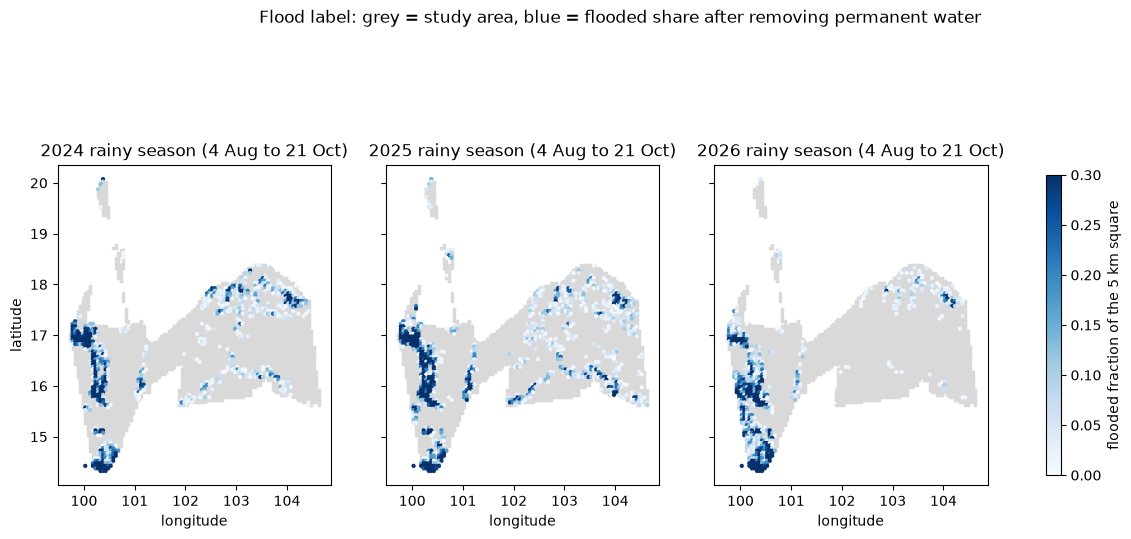

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 6.5), sharey=True)
for a, y in zip(ax, YEARS):
    t = labels[labels.season == y]
    a.scatter(cells.lon, cells.lat, c="0.85", s=3)                    # study area in grey
    wet = t[t.flooded_frac > 0]
    sc = a.scatter(wet.lon, wet.lat, c=wet.flooded_frac, s=4, cmap="Blues", vmin=0, vmax=0.3)
    a.set_title(f"{y} rainy season (4 Aug to 21 Oct)")
    a.set_aspect("equal"); a.set_xlabel("longitude")
ax[0].set_ylabel("latitude")
fig.colorbar(sc, ax=ax, shrink=0.6, label="flooded fraction of the 5 km square")
fig.suptitle("Flood label: grey = study area, blue = flooded share after removing permanent water")
savefig(fig, "fig_labels_maps", FIG_DIR)
plt.show()

**What to check:** flooding repeats in the same places (the central plain and the northeast river valleys), and 2026 shifts toward the central and eastern areas, as described in the proposal.

## Summary

The labels are rebuilt from the frozen data with the October rules, and the proposal numbers are reproduced, so nothing changed by accident. The one deliberate change is the extra 2026 pass from the data freeze.

**Save the work** (in a terminal):
```bash
cd ~/thailand-flood-ml
git add -A
git commit -m "Notebook 02: flood labels from frozen data, proposal numbers reproduced"
git push
```
Next: `03_build_features.ipynb` (rainfall, terrain, rivers, flood history).